# Site analysis: what imagery exists at my sites, and getting it

Searches every catalog you can access (CSDA STAC, NASA CMR's CSDA archive, vendor APIs) at a set of
sites, then shows **what** exists, **where** and **when**, how the acquisitions **vary** (cloud, GSD,
view and sun geometry), and **downloads** the selection from CSDA STAC or Earthdata with your
credentials.

| Step | Output |
|---|---|
| 1. Catalog overview | first/last acquisition and timeline per collection (catalog-wide) |
| 2. Search | one table: common columns (provider, affiliation, constellation, sensor, angles, ...) + all vendor properties |
| 3. What and where | counts per site and sensor, monthly heatmaps |
| 4. Variation | distributions by constellation, skyplots per site |

Library: `lib/multistac.py` (search), `lib/multistac_plots.py`, `lib/multistac_download.py`.
Profiles and vocabularies: `lib/stac_providers.yaml`, `lib/sensor_catalog.yaml`.

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
import pandas as pd
import matplotlib.pyplot as plt
import multistac, multistac_plots, multistac_download
for m in (multistac, multistac_plots, multistac_download):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

## Parameters

In [2]:
SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_NAMES = None #['San Francisco', 'Railroad Valley','Belo Horizonte']   # None = all sites in the file
SITE_FILTERS = {'Remote Sensing Domain': 'Optical'}   # {field: value} on the sites file; str = contains (case-insensitive), list = exact values; None = no filter

START, END = '2020-01-01', '2026-12-31'
MONTHS = None              # e.g. [6, 7, 8]
CLOUD_COVER_MAX = 0     # e.g. 20; None keeps SAR/DEM/no-cloud-cover collections

CSDA_INCLUDE = ['satellogic']          # [] = do not search CSDA at all
CSDA_EXCLUDE = []
EXTRA_PROVIDERS = {
    'satellogic': ['quickview-visual'
                   #,'quickview-visual-thumb'
                  ],   # the full-resolution archive (~0.78 m); add 'quickview-visual-thumb' only if you want thumbnails
}

CACHE_DIR = '/explore/nobackup/people/pmontesa/stac_cache/multistac'
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/site_analysis'

In [3]:
sites = multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD, filters=SITE_FILTERS)
if SITE_NAMES:
    sites = sites[sites.site_name.isin(SITE_NAMES)]
print(len(sites), 'sites')
#sites.explore(tooltip='site_name') if len(sites) < 300 else sites.plot()

/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL/../../../libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL/../../../libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL/../../../libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL/../../../libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL

58 sites


In [4]:
# CSDA STAC collections: only CSDA_INCLUDE (if set), minus CSDA_EXCLUDE
csda_collections = multistac.collections('csda')
CSDA_IDS = [c for c in csda_collections['id']
            if (CSDA_INCLUDE is None or c in CSDA_INCLUDE) and c not in CSDA_EXCLUDE]
missing = set(CSDA_INCLUDE or []) - set(csda_collections['id'])
if missing:
    print('Not in CSDA STAC (check spelling):', sorted(missing))
print(f'{len(CSDA_IDS)} of {len(csda_collections)} CSDA STAC collections:', ', '.join(CSDA_IDS))

PROVIDERS = {'csda': CSDA_IDS, **EXTRA_PROVIDERS}
multistac.list_providers()[['provider', 'display_name', 'api', 'enabled']]

1 of 27 CSDA STAC collections: satellogic


,provider,display_name,api,enabled
0,csda,CSDA STAC,stac,True
1,satellogic,Satellogic,stac,True
2,csda-cmr,Earthdata CMR – CSDA,cmr,True
3,hydrosat,Hydrosat,stac,True
4,vantor,Vantor,stac,True
5,kuva,Kuva Space,kuva_products,True


## 1. Catalog overview
Catalog-wide (not just your sites). Collections whose catalog reports no counts show their date range as a band.

No catalog counts from this API (use res.by_month()): csda/satellogic


,provider,collection,title,first,last,total,dates_from,in_window
0,csda,satellogic,Satellogic,2021-02-02,2026-11-05,n/a,items,True
1,satellogic,quickview-visual,QuickView Visual,2020-03-16,2026-11-07,"17,909,793",items,True


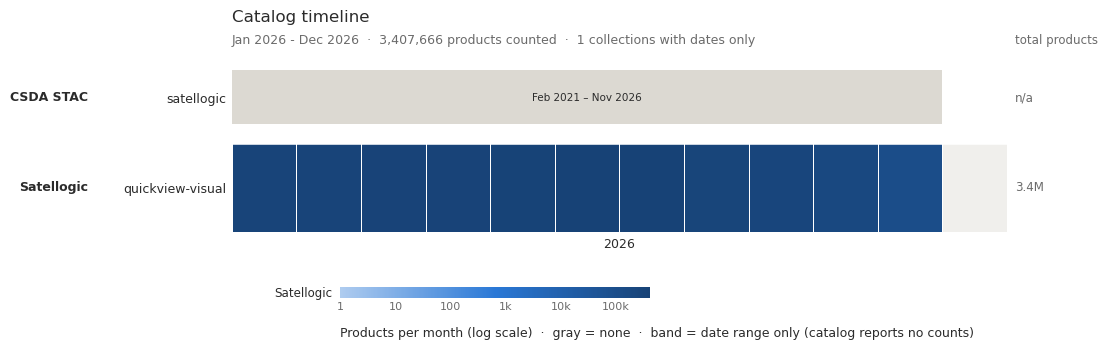

In [5]:
catalog_overview = multistac.overview(PROVIDERS, START, END)
catalog_months = multistac.overview_by_month(PROVIDERS, START, END)
multistac_plots.plot_month_heatmap(catalog_months, spans=catalog_overview, color_by='provider',
                                   start=START[:7], end=END[:7], title='Catalog timeline');
catalog_overview

## 2. Search the sites

In [6]:
%%time
res = multistac.search(sites, START, END, PROVIDERS, months=MONTHS, split='month',   # busy sites fail (HTTP 502) on longer windows
                       cloud_cover_max=CLOUD_COVER_MAX, cache_dir=CACHE_DIR)
print(res)
res.log[res.log.status == 'failed']

searches: 100%|██████████| 116/116 [03:20<00:00,  1.73s/it] 


SearchResult(4289 rows, 4289 unique items, 3 failed tasks)
CPU times: user 1.65 s, sys: 199 ms, total: 1.85 s
Wall time: 3min 22s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds
78,satellogic,quickview-visual,Gobabeb,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0.0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,34.7
86,satellogic,quickview-visual,La Crau,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0.0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,48.1
105,satellogic,quickview-visual,Railroad Valley,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0.0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,79.2


In [7]:
res.summary()

,provider,collection,processing_level,rows,products,acquisitions,sites,in_csda
0,csda,satellogic,L1D_SR,7,7,7,5,7
1,satellogic,quickview-visual,QUICKVIEW_VISUAL,4282,4282,1367,29,18


## 3. What do we have, and where?

**These counts are products, not acquisitions.** Each row of `res.gdf` is one catalog item, i.e. one *product*, and one acquisition (one satellite collect) is often delivered as several products:

- **Spectral products:** the panchromatic, multispectral and pansharpened products of one collect are separate items, e.g. Legion `P2AS` / `M2AS` / `S3DS`, Airbus `P` / `MS` / `PMS`, Maxar `P1BS` / `M1BS` in CMR. The `spectral_mode` column says which.
- **Processing levels:** the same collect at several levels (Legion `LV1B` / `LV2A` / `LV3D`, Satellogic `L1B` / `L1D_SR`).
- **File formats:** BlackSky delivers each collect as up to four items (GeoTIFF and NITF, ortho and non-ortho).

`acquisition_id` groups the products of one collect, so count `acquisition_id.nunique()` to answer "how many times was this site imaged?", and `id.nunique()` for "how many products are there?". The table below shows both.

**The plots take `count='products'` or `count='acquisitions'`** (`res.by_month(..., count=...)`, `plot_density_maps(..., count=...)`, `plot_distributions(..., count=...)`), and every title, axis and colorbar says which one is counted. Skyplots default to acquisitions (the products of one collect share its geometry).

Overlapping sites (e.g. WLEF and its skycams) also share products: count by `site_group` to count each product once per group (see the parameters section).


In [9]:
# Products vs acquisitions per constellation, and the product mix (spectral_mode x processing level)
gdf = res.gdf.drop_duplicates(['provider', 'id'])

gdf = gdf[gdf['satl:product_version'].str.split('.').str[0].astype(int) >= 1]

counts = gdf.groupby(['affiliation', 'constellation']).agg(products=('id', 'size'), acquisitions=('acquisition_id', 'nunique'),
                                                        sites=('site_name', 'nunique'))
counts['products_per_acquisition'] = (counts.products / counts.acquisitions).round(2)
display(counts.sort_values('products', ascending=False))
gdf.groupby(['constellation', 'spectral_mode', 'processing_level'], dropna=False).size().unstack('processing_level', fill_value=0)


,,products,acquisitions,sites,products_per_acquisition
affiliation,constellation,,,,
Satellogic,Aleph-1,4289,1369,29,3.13


,processing_level,L1D_SR,QUICKVIEW_VISUAL
constellation,spectral_mode,,
Aleph-1,ms,7,4282


### Version number: `satellogic` doesnt tell us, but we assume all data starting in 2026 will be v2 - confirm with vendor

In [10]:
print(gdf.groupby('provider')['satl:product_version'].unique())

provider
csda                                  [2.0.1]
satellogic    [1.9.0, 1.10.1, 1.11.0, 1.10.0]
Name: satl:product_version, dtype: object


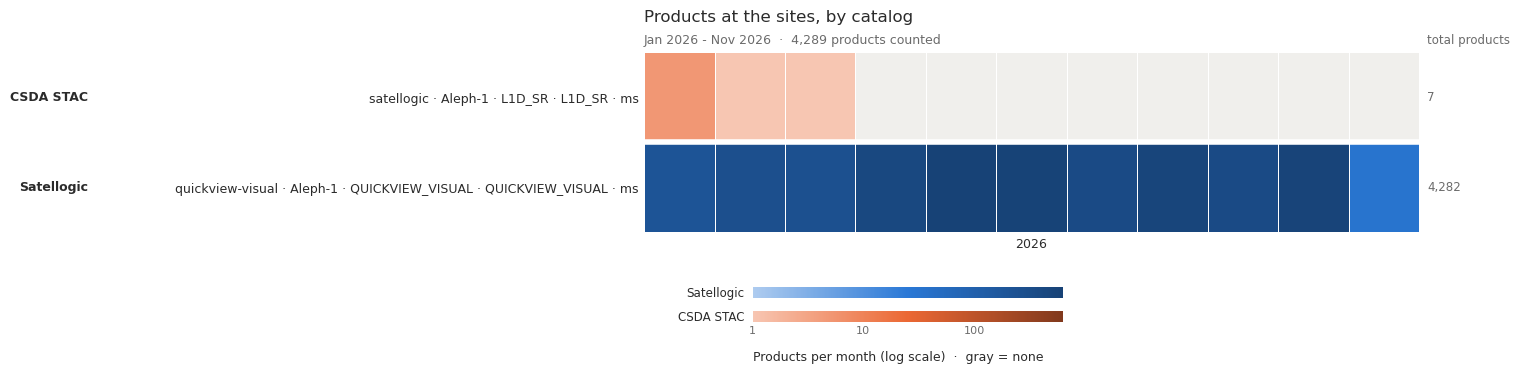

In [12]:
multistac_plots.plot_month_heatmap(res.by_month(['provider', 'collection','constellation','product_type','processing_level','spectral_mode'], count='products'), color_by='provider',
                                   title='Products at the sites, by catalog');

quickview-visual: 4282 products from 1367 acquisitions at 29 sites
quickview-visual: 4282 products from 1367 acquisitions at 29 sites


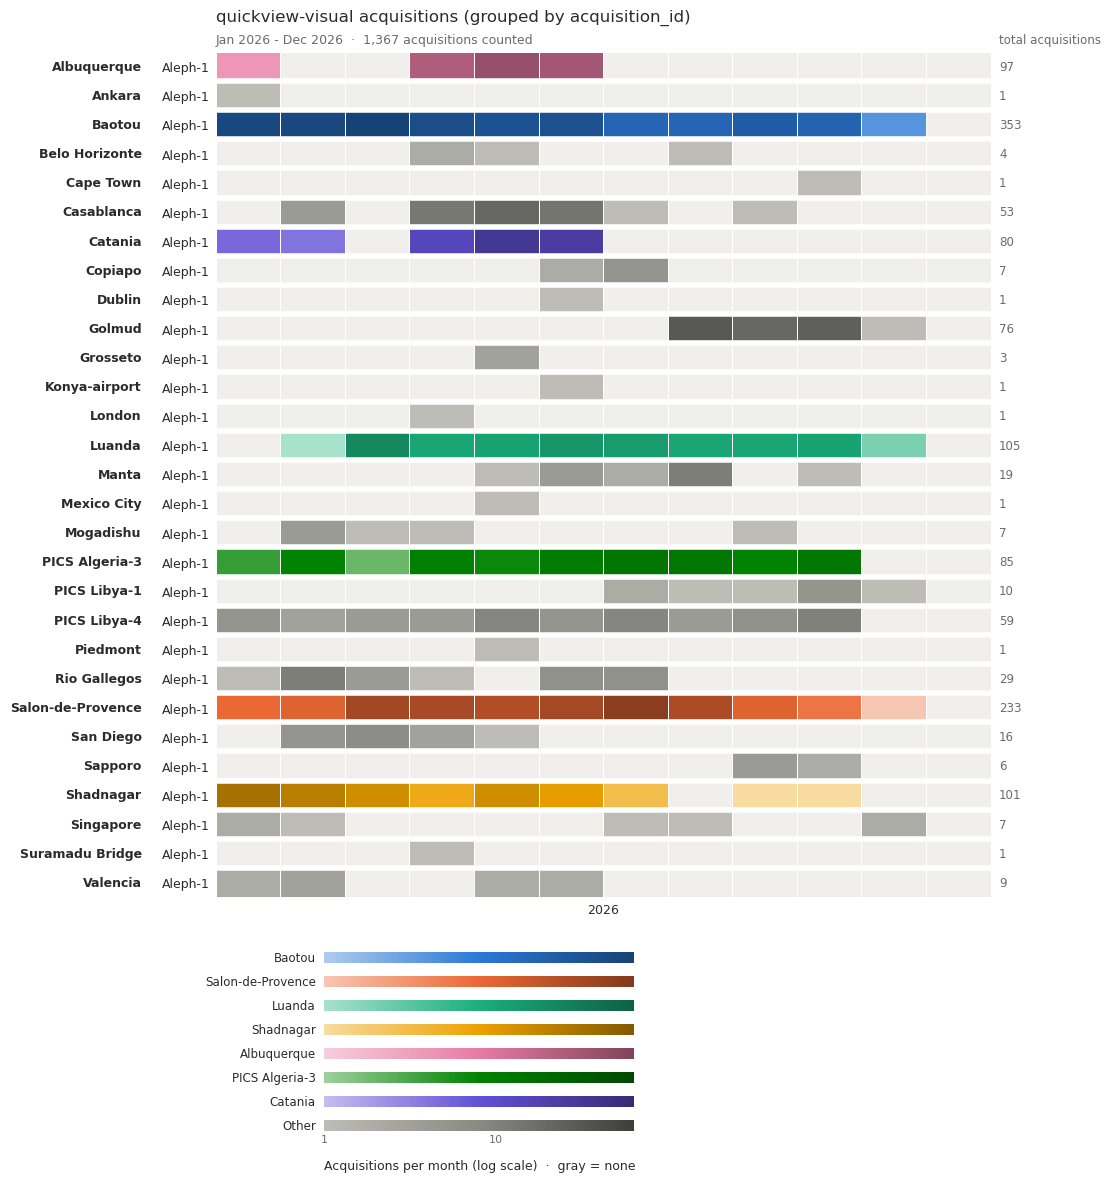

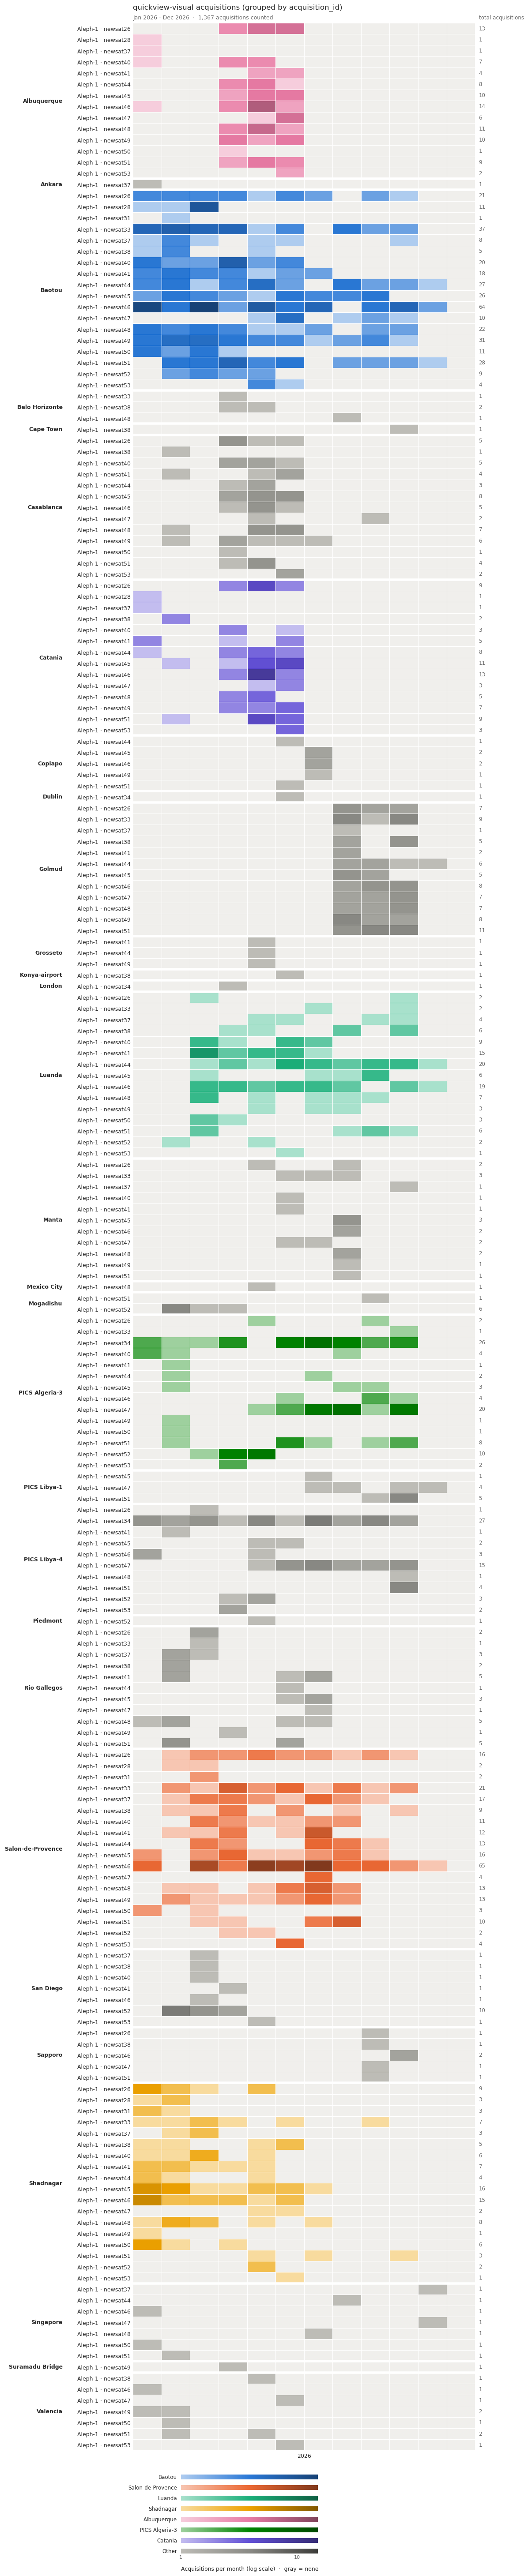

In [13]:
# quickview-visual only, counted by acquisition: the products of one collect (one acquisition_id) count once.
# Uses gdf from above (product_version >= 1). BY sets the rows, e.g. ['site_name'] or ['constellation', 'platform'].
BY = ['site_name','constellation', 'platform']
qv = gdf[gdf.collection == 'quickview-visual']

print(f"quickview-visual: {qv.id.nunique()} products from {qv.acquisition_id.nunique()} acquisitions at {qv.site_name.nunique()} sites")
multistac_plots.plot_month_heatmap(multistac.month_table(qv, BY[0:2], count='acquisitions'), color_by='site_name', max_rows=None,
                                   start=START[:7], end=END[:7], title='quickview-visual acquisitions (grouped by acquisition_id)');

print(f"quickview-visual: {qv.id.nunique()} products from {qv.acquisition_id.nunique()} acquisitions at {qv.site_name.nunique()} sites")
multistac_plots.plot_month_heatmap(multistac.month_table(qv, BY, count='acquisitions'), color_by='site_name', max_rows=None,
                                   start=START[:7], end=END[:7], title='quickview-visual acquisitions (grouped by acquisition_id)');


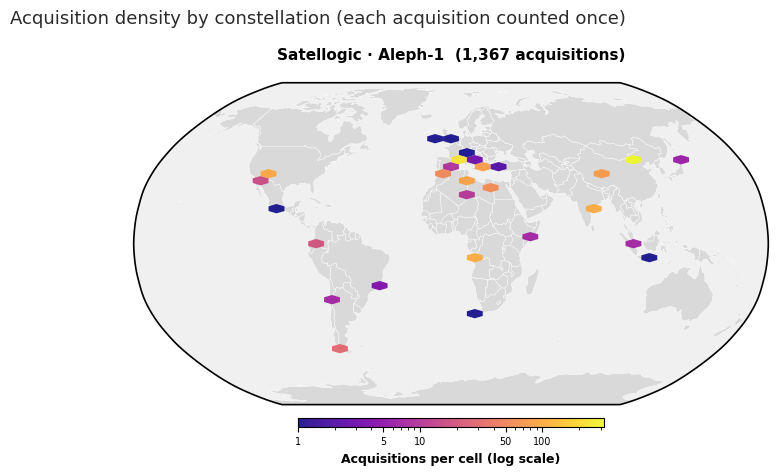

In [14]:
multistac_plots.plot_density_maps(qv, facet_by=['affiliation','constellation'], max_facets=30, gridsize=40,
                                  count='acquisitions', title='Acquisition density by constellation (each acquisition counted once)');

## 4. Inherent variation: cloud, resolution, view and sun geometry

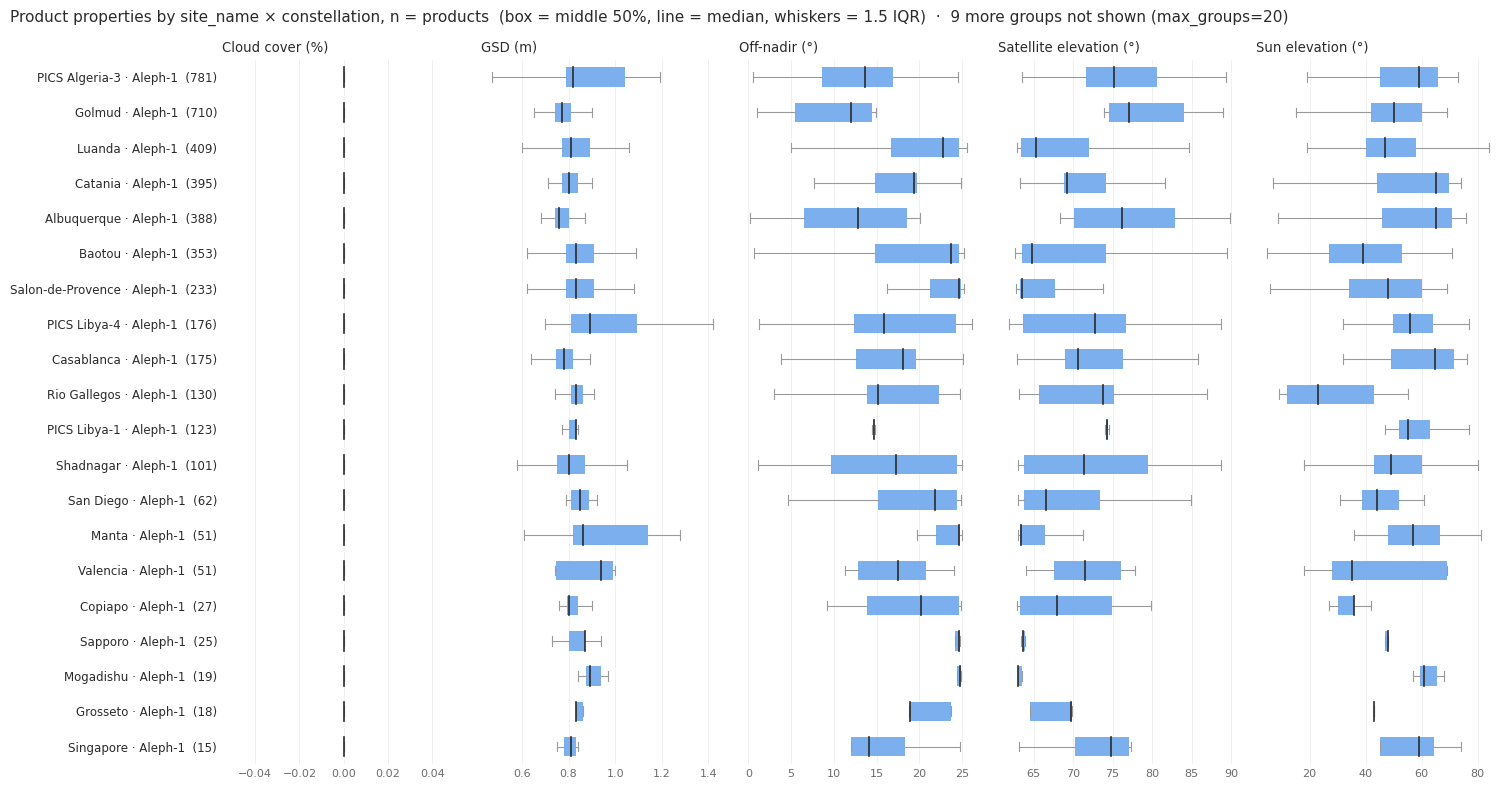

In [15]:
multistac_plots.plot_distributions(qv, count='products',   # GSD differs between a collect's pan and MS products
                    by = ['site_name', 'constellation']
                                  );

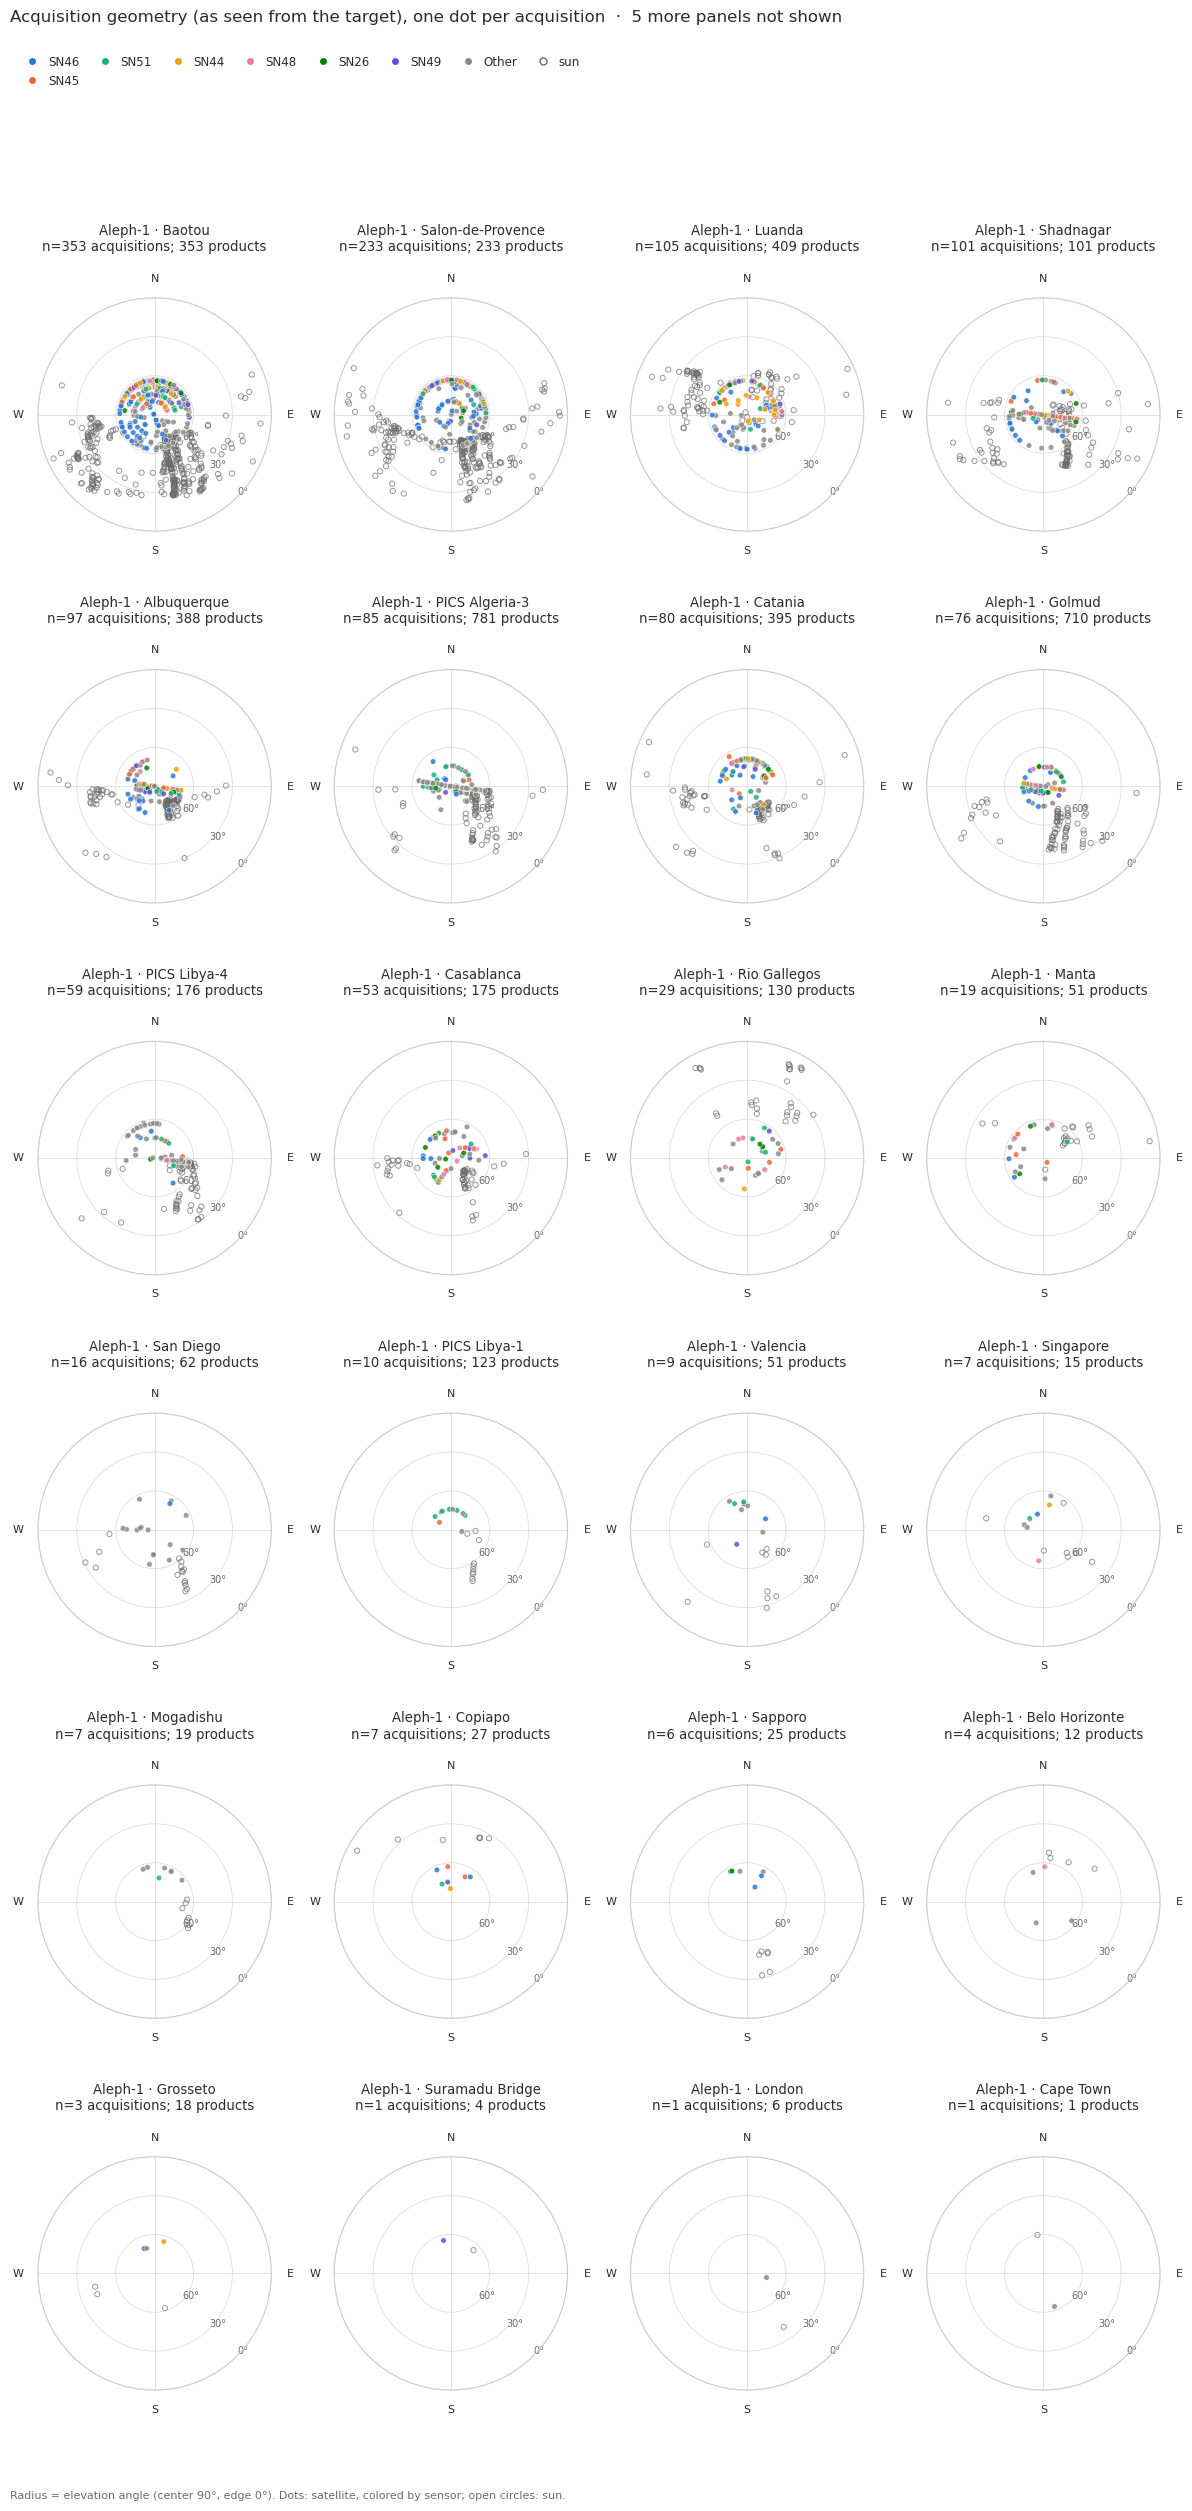

In [16]:
# Satellite and sun positions as seen from each site, one dot per acquisition (satellite colored by sensor).
# CMR rows have no azimuths and are left out; sat_elevation_source says when elevation is estimated.
multistac_plots.plot_skyplot(qv, facet_by=['constellation','site_group'], color_by='sensor', panel_size=3);

## Publish to the dashboard

Updates this vendor's tab in `html/archive_first_look.html`, the page for the SMEs: good acquisitions by site and sensor, with the limits set on the page. It runs its own search with no cloud limit so the SMEs can change them, and leaves the results above alone. Commit and push the page and `html/archive_first_look_data/` to publish.

In [ ]:
import archive_dashboard
importlib.reload(archive_dashboard)
dash = multistac.search(sites, START, END, PROVIDERS, split='month')   # no cloud limit, no cache; busy sites fail (HTTP 502) in one request
print(dash)
published = dash.gdf[dash.gdf.provider.eq('csda') | (dash.gdf['satl:product_version'].astype(str).str.split('.').str[0].astype(float) >= 1)]
archive_dashboard.publish('satellogic', published, sites, SITES, SITE_NAME_FIELD, START, END, dash.log)